### Задача 1

Для набора данных, представленных таблицей ниже:

| $x_{1}$ | $x_{2}$ |
|--------:|:--------|
| 4 | 4 |
| -1 | -1 |
| 3 | 0 |
| 3 | 1 |
| 2 | 0 |
| 1 | 2 |

- Найти ковариационную матрицу
- Найти главные компоненты (собственные векторы этой матрицы)
- Вычислить проекции исходных данных на первую главную компоненту
- Изобразите центрированные данные и главные компоненты в исходном признаковом пространстве

#### Решение

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
X = np.array([
    [4, 4],
    [-1, -1],
    [3, 0],
    [3, 1],
    [2, 0],
    [1, 2]
], dtype=float)

In [3]:
X_mean = X.mean(axis=0)
X_centered = X - X_mean

In [4]:
n = X_centered.shape[0]
cov_matrix = (X_centered.T @ X_centered) / n

In [5]:
eigvals, eigvecs = np.linalg.eig(cov_matrix)

In [6]:
idx = np.argsort(eigvals)[::-1]
eigvals = eigvals[idx]
eigvecs = eigvecs[:, idx]

In [7]:
first_pc = eigvecs[:, 0]
projections = X_centered @ first_pc
X_projected = np.outer(projections, first_pc)

In [8]:
print(f"Ковариационная матрица:\n{cov_matrix}")
print(f"\nСобственные значения\n{eigvals}")
print(f"\nСобственные векторы:\n{eigvecs}")
print(f"\nПроекции:\n{projections}")

Ковариационная матрица:
[[2.66666667 1.66666667]
 [1.66666667 2.66666667]]

Собственные значения
[4.33333333 1.        ]

Собственные векторы:
[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]

Проекции:
[ 3.53553391e+00 -3.53553391e+00 -1.11022302e-16  7.07106781e-01
 -7.07106781e-01  1.11022302e-16]


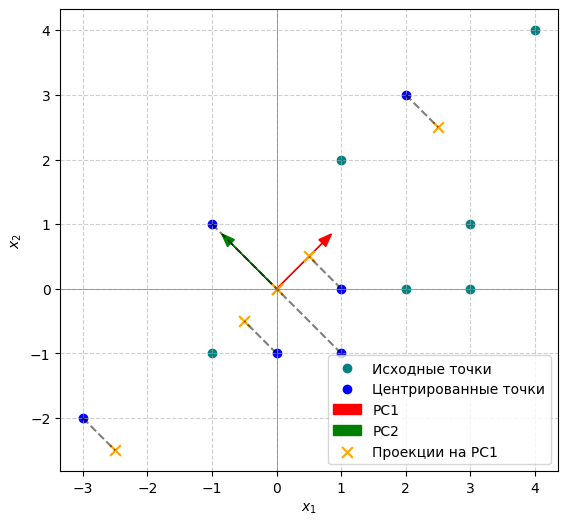

In [11]:
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], color="teal", label="Исходные точки")
plt.scatter(X_centered[:, 0], X_centered[:, 1], color="blue", label="Центрированные точки")

plt.arrow(0, 0, eigvecs[0, 0], eigvecs[1, 0],
          head_width=0.15, head_length=0.2, fc="red", ec="red", linewidth=1, label="PC1")
plt.arrow(0, 0, eigvecs[0, 1], eigvecs[1, 1],
          head_width=0.15, head_length=0.2, fc="green", ec="green", linewidth=1, label="PC2")

for i in range(len(X_centered)):
    plt.plot([X_centered[i, 0], X_projected[i, 0]],
             [X_centered[i, 1], X_projected[i, 1]],
             'k--', alpha=0.5)

plt.scatter(X_projected[:, 0], X_projected[:, 1], color="orange", marker="x", s=60, label="Проекции на PC1")

plt.axhline(0, color='gray', linewidth=0.5)
plt.axvline(0, color='gray', linewidth=0.5)
plt.gca().set_aspect('equal', adjustable='box')
plt.legend()
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

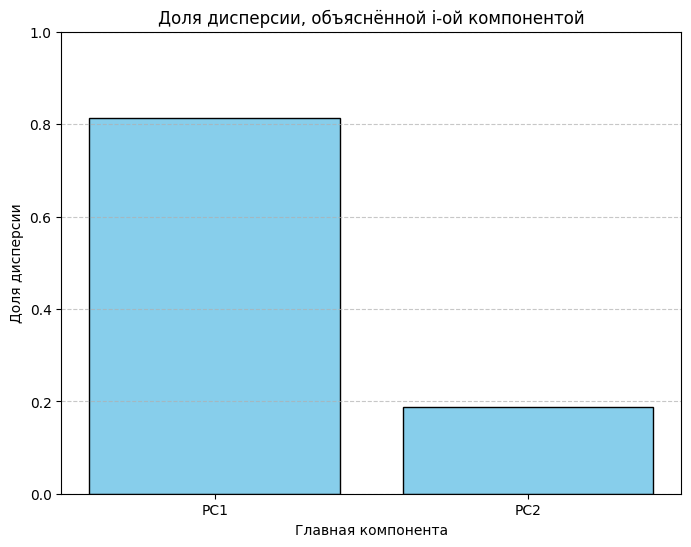

In [12]:
plt.figure(figsize=(8, 6))
plt.bar(np.arange(len(eigvals)), eigvals/eigvals.sum(), color="skyblue", edgecolor="black")
plt.title("Доля дисперсии, объяснённой i-ой компонентой")
plt.xlabel("Главная компонента")
plt.ylabel("Доля дисперсии")
plt.xticks(np.arange(len(eigvals)), [f"PC{i+1}" for i in range(len(eigvals))])
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

#### PCA в sklearn

In [13]:
from sklearn.decomposition import PCA

In [14]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

In [15]:
display(pca.components_)

array([[ 0.70710678,  0.70710678],
       [ 0.70710678, -0.70710678]])

In [16]:
display(eigvecs)

array([[ 0.70710678, -0.70710678],
       [ 0.70710678,  0.70710678]])

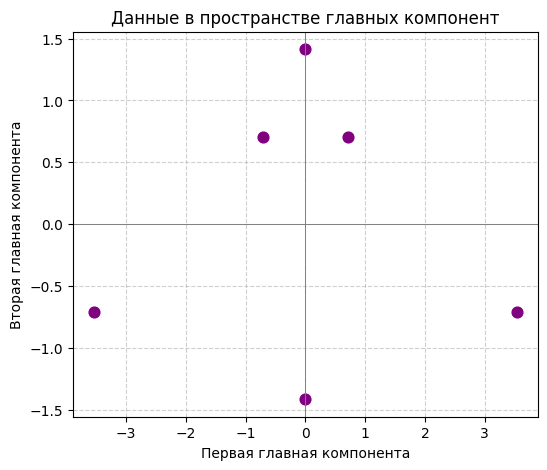

In [17]:
plt.figure(figsize=(6, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], color="purple", s=60)
plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.title("Данные в пространстве главных компонент")
plt.grid(True, linestyle="--", alpha=0.6)
plt.axhline(0, color="gray", linewidth=0.7)
plt.axvline(0, color="gray", linewidth=0.7)
plt.show()

In [18]:
print(f"Доли объяснённой дисперсии: {pca.explained_variance_ratio_}")

Доли объяснённой дисперсии: [0.8125 0.1875]


### Задача 12

- Провести нормировку данных
- Найти первые 2 главные компоненты
- Найти долю дисперсии, объясняемую первыми двумя компонентами
- Изобразить данные в пространстве первых двух главных компонент
- Проинтерпретировать главные компоненты
- Подобрать оптимальное число кластеров (можно так же проделать это на основе картинки с шага 4). Проинтерпретировать кластеры

In [19]:
!gdown https://drive.google.com/uc?id=1tYMR_J3RbXN8ePrHkAuCinhlrOqnoN1f

Downloading...
From: https://drive.google.com/uc?id=1tYMR_J3RbXN8ePrHkAuCinhlrOqnoN1f
To: /content/players_dataset.csv
100% 8.38M/8.38M [00:00<00:00, 64.8MB/s]


In [20]:
import pandas as pd
pd.options.display.max_columns = 50

In [21]:
data = pd.read_csv("players_dataset.csv")

In [22]:
display(data)

,potential,crossing,finishing,heading_accuracy,short_passing,volleys,dribbling,curve,free_kick_accuracy,long_passing,ball_control,acceleration,sprint_speed,agility,reactions,balance,shot_power,jumping,stamina,strength,long_shots,aggression,interceptions,positioning,vision,penalties,marking,standing_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes,preferred_foot_right,attacking_work_rate_medium,attacking_work_rate_high,attacking_work_rate_low
0,79.0,66.0,69.0,58.0,69.0,60.0,74.0,67.0,70.0,59.0,73.0,78.0,80.0,91.0,64.0,81.0,72.0,71.0,68.0,49.0,69.0,64.0,31.0,73.0,71.0,58.0,25.0,20.0,13.0,13.0,7.0,10.0,7.0,0,1,0,0
1,73.0,50.0,65.0,64.0,64.0,53.0,67.0,60.0,43.0,47.0,70.0,68.0,79.0,59.0,59.0,51.0,67.0,50.0,54.0,81.0,62.0,43.0,23.0,56.0,44.0,64.0,23.0,27.0,6.0,10.0,13.0,15.0,11.0,1,1,0,0
2,80.0,70.0,69.0,40.0,74.0,52.0,81.0,73.0,77.0,66.0,80.0,81.0,78.0,77.0,73.0,76.0,74.0,34.0,79.0,65.0,75.0,52.0,33.0,78.0,75.0,62.0,34.0,47.0,12.0,11.0,15.0,11.0,9.0,1,1,0,0
3,73.0,6.0,19.0,10.0,45.0,10.0,10.0,14.0,13.0,39.0,21.0,32.0,40.0,34.0,53.0,38.0,13.0,61.0,49.0,60.0,12.0,28.0,39.0,11.0,37.0,16.0,23.0,20.0,64.0,59.0,56.0,51.0,58.0,1,1,0,0
4,80.0,58.0,46.0,57.0,68.0,35.0,65.0,81.0,75.0,66.0,63.0,66.0,69.0,63.0,70.0,65.0,82.0,83.0,64.0,74.0,66.0,64.0,71.0,52.0,62.0,46.0,67.0,69.0,15.0,9.0,7.0,13.0,9.0,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49006,85.0,43.0,75.0,69.0,58.0,57.0,70.0,52.0,43.0,41.0,73.0,77.0,71.0,75.0,62.0,79.0,68.0,75.0,55.0,77.0,53.0,78.0,31.0,73.0,59.0,61.0,22.0,21.0,11.0,8.0,13.0,12.0,8.0,1,0,1,0
49007,77.0,51.0,23.0,81.0,72.0,13.0,55.0,40.0,39.0,66.0,72.0,55.0,65.0,55.0,66.0,58.0,43.0,84.0,74.0,82.0,17.0,84.0,84.0,30.0,59.0,60.0,76.0,74.0,9.0,13.0,8.0,13.0,6.0,1,1,0,0
49008,62.0,55.0,35.0,46.0,73.0,59.0,61.0,51.0,61.0,65.0,56.0,64.0,56.0,62.0,68.0,72.0,47.0,74.0,81.0,73.0,44.0,66.0,47.0,37.0,57.0,62.0,45.0,63.0,8.0,13.0,5.0,9.0,5.0,1,1,0,0
49009,84.0,84.0,61.0,51.0,92.0,71.0,79.0,87.0,90.0,94.0,93.0,55.0,55.0,69.0,87.0,81.0,80.0,33.0,61.0,65.0,84.0,62.0,68.0,56.0,94.0,84.0,45.0,65.0,6.0,5.0,10.0,9.0,8.0,1,0,0,1


#### EDA

In [23]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49011 entries, 0 to 49010
Data columns (total 37 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   potential                   49011 non-null  float64
 1   crossing                    49011 non-null  float64
 2   finishing                   49011 non-null  float64
 3   heading_accuracy            49011 non-null  float64
 4   short_passing               49011 non-null  float64
 5   volleys                     49011 non-null  float64
 6   dribbling                   49011 non-null  float64
 7   curve                       49011 non-null  float64
 8   free_kick_accuracy          49011 non-null  float64
 9   long_passing                49011 non-null  float64
 10  ball_control                49011 non-null  float64
 11  acceleration                49011 non-null  float64
 12  sprint_speed                49011 non-null  float64
 13  agility                     490

In [24]:
data.describe()

,potential,crossing,finishing,heading_accuracy,short_passing,volleys,dribbling,curve,free_kick_accuracy,long_passing,ball_control,acceleration,sprint_speed,agility,reactions,balance,shot_power,jumping,stamina,strength,long_shots,aggression,interceptions,positioning,vision,penalties,marking,standing_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes,preferred_foot_right,attacking_work_rate_medium,attacking_work_rate_high,attacking_work_rate_low
count,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.00000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000,49011.000000
mean,73.435984,55.084736,49.981331,57.218135,62.389260,49.477546,59.266083,52.940115,49.34984,57.002204,63.389341,67.712514,68.100284,65.950481,66.059864,65.121830,61.733142,66.928118,66.955051,67.429679,53.322213,60.792251,51.737855,55.744241,57.794801,54.963355,46.606027,50.198506,14.762359,16.026851,20.642856,16.067046,16.371488,0.756381,0.694987,0.235886,0.048622
std,6.583908,17.230102,19.070501,16.499358,14.159569,18.224604,17.748379,18.257950,17.77850,14.352644,15.229064,12.988051,12.546859,12.955059,9.116255,13.097579,16.182557,10.975155,13.169626,12.052992,18.340714,16.092625,19.499038,18.448890,15.117994,15.537221,21.183263,21.430312,16.920322,15.937427,21.237651,16.153634,17.267390,0.429270,0.460418,0.424556,0.215078
min,39.000000,2.000000,1.000000,2.000000,3.000000,2.000000,2.000000,2.000000,1.00000,5.000000,5.000000,14.000000,13.000000,19.000000,17.000000,15.000000,3.000000,14.000000,14.000000,12.000000,1.000000,8.000000,2.000000,2.000000,1.000000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,69.000000,45.000000,34.000000,49.000000,57.000000,36.000000,52.000000,41.000000,36.00000,49.000000,59.000000,61.000000,62.000000,58.000000,61.000000,58.000000,54.000000,60.000000,61.000000,60.000000,41.000000,51.000000,33.000000,45.000000,49.000000,45.000000,25.000000,29.000000,7.000000,8.000000,8.000000,8.000000,8.000000,1.000000,0.000000,0.000000,0.000000
50%,74.000000,59.000000,53.000000,60.000000,65.000000,52.000000,64.000000,56.000000,50.00000,59.000000,67.000000,69.000000,69.000000,68.000000,67.000000,67.000000,65.000000,68.000000,69.000000,69.000000,58.000000,64.000000,56.000000,60.000000,60.000000,57.000000,50.000000,56.000000,10.000000,11.000000,12.000000,11.000000,11.000000,1.000000,1.000000,0.000000,0.000000
75%,78.000000,68.000000,65.000000,68.000000,72.000000,64.000000,72.000000,67.000000,63.00000,67.000000,73.000000,77.000000,77.000000,75.000000,72.000000,74.000000,73.000000,74.000000,76.000000,76.000000,67.000000,73.000000,68.000000,69.000000,69.000000,66.000000,66.000000,69.000000,13.000000,15.000000,15.000000,15.000000,15.000000,1.000000,1.000000,0.000000,0.000000
max,97.000000,95.000000,97.000000,98.000000,97.000000,92.000000,97.000000,94.000000,95.00000,97.000000,97.000000,97.000000,97.000000,96.000000,96.000000,96.000000,96.000000,96.000000,96.000000,96.000000,96.000000,97.000000,96.000000,95.000000,97.000000,96.000000,94.000000,95.000000,94.000000,91.000000,97.000000,96.000000,96.000000,1.000000,1.000000,1.000000,1.000000


##### `ProfileReport`

In [7]:
# pip install -q -U ydata-profiling

In [8]:
from ydata_profiling import ProfileReport

/tmp/ipykernel_2967/44057814.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


In [9]:
profile = ProfileReport(data)
profile.to_file("output.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 37/37 [00:04<00:00,  8.41it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [10]:
profile

Output hidden; open in https://colab.research.google.com to view.

#### Подготовка данных



In [25]:
numeric_cols = data.select_dtypes(include=[np.number]).columns.tolist()
X = data[numeric_cols].copy()

In [26]:
from sklearn.preprocessing import StandardScaler

In [27]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=numeric_cols)

#### PCA

In [28]:
from sklearn.decomposition import PCA

In [29]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [30]:
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

In [31]:
print(f"Доля дисперсии, объяснённая PC1: {explained_variance_ratio[0]:.3f}")
print(f"Доля дисперсии, объяснённая PC2: {explained_variance_ratio[1]:.3f}")
print(f"Общая доля дисперсии, объяснённая PC1 и PC2: {cumulative_variance[1]:.3f}")

Доля дисперсии, объяснённая PC1: 0.425
Доля дисперсии, объяснённая PC2: 0.133
Общая доля дисперсии, объяснённая PC1 и PC2: 0.557


In [32]:
pca_full = PCA()
pca_full.fit(X_scaled)

PCA()

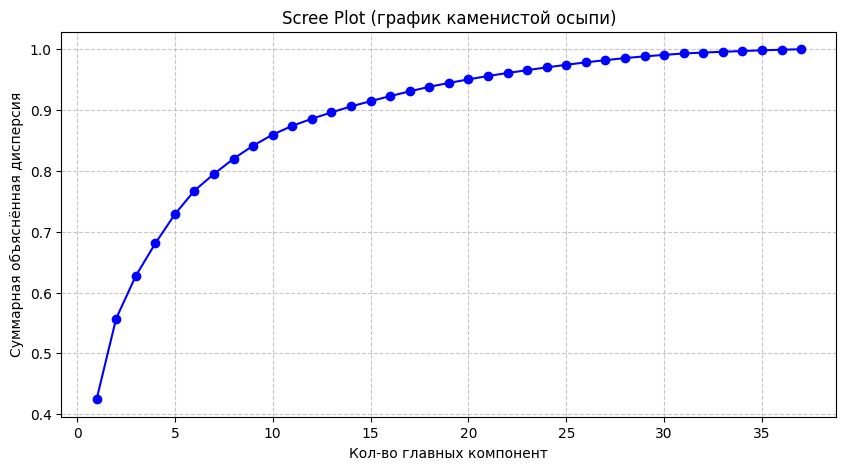

In [33]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(pca_full.explained_variance_ratio_) + 1),
         np.cumsum(pca_full.explained_variance_ratio_), 'bo-')
plt.xlabel("Кол-во главных компонент")
plt.ylabel("Суммарная объяснённая дисперсия")
plt.title("Scree Plot (график каменистой осыпи)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

#### Визуализация в пространстве PC

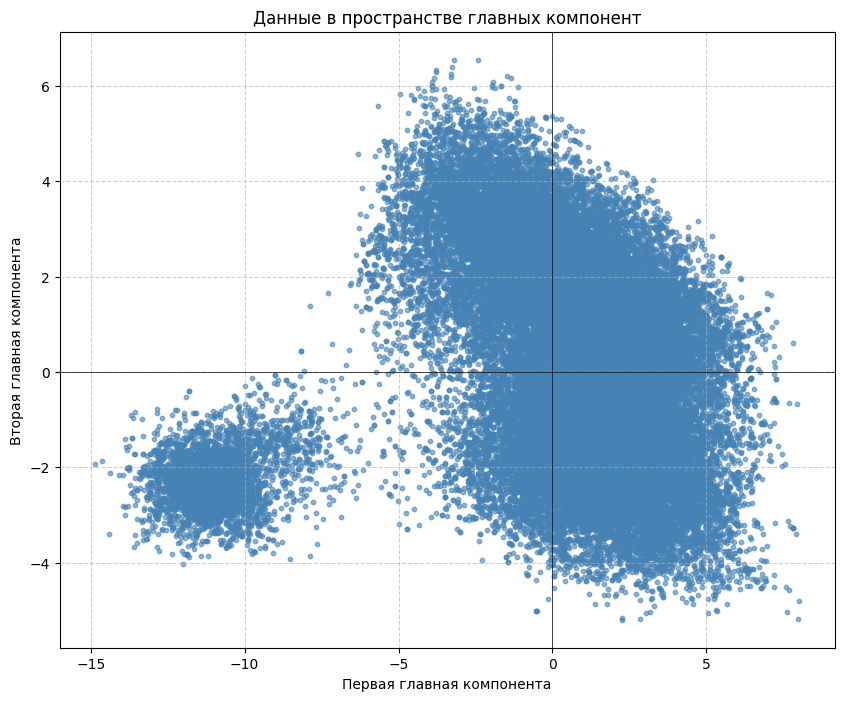

In [34]:
plt.figure(figsize=(10, 8))
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.6, s=10, color="steelblue")
plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.title("Данные в пространстве главных компонент")
plt.grid(True, linestyle='--', alpha=0.6)
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.show()

In [35]:
var = "gk_diving"

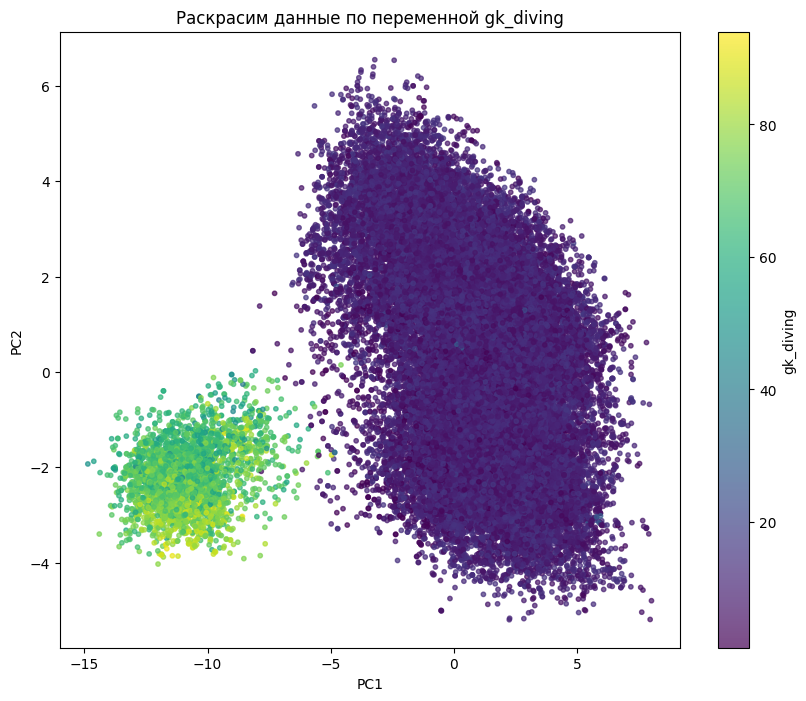

In [36]:
var_vals = X[var].values
plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=var_vals, cmap="viridis", s=10, alpha=0.7)
plt.colorbar(scatter, label=var)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title(f"Раскрасим данные по переменной {var}")
plt.show()

#### Объясняем PC

In [37]:
def pca_explanation_plot(loadings_matrix: np.array, feature_names: np.array, component_number: int=0) -> None:
    """
    Args:
        loadings_matrix: матрица нагрузок - из неё достаём выражение компонент через изначальные признаки
        feature_names: название фичей
        component_number: какую компоненту визуализировать
    Return:
        Рисуем барплот
    """
    assert component_number < len(loadings_matrix), 'Матрица нагрузок содержит меньшее число компонент!'

    # sorted_features = np.array(feature_names)[np.argsort(loadings_matrix[component_number])[::-1]]
    # sorted_loadings = np.sort(loadings_matrix[component_number])[::-1]

    # if len(feature_names) > 20:
    #     sorted_features = np.array(sorted_features[:10].tolist() + sorted_features[-10:].tolist())
    #     sorted_loadings = np.array(sorted_loadings[:10].tolist() + sorted_loadings[-10:].tolist())

    # plt.figure(figsize=(8, 10))
    # plt.title(f'Главная компонента №{component_number + 1}', fontsize=15)
    # plt.barh(sorted_features, sorted_loadings)
    # plt.yticks(rotation=0, fontsize=15)
    loadings = loadings_matrix[component_number]
    loading_df = pd.DataFrame({
        'feature': feature_names,
        'loading': loadings
    })

    loading_df['abs_loading'] = np.abs(loading_df['loading'])
    loading_df = loading_df.sort_values('abs_loading', ascending=False)

    if len(feature_names) > 20:
        top_features = loading_df.head(10)
        bottom_features = loading_df.tail(10)
        plot_df = pd.concat([top_features, bottom_features], ignore_index=True)
        plot_df = plot_df.sort_values('loading', ascending=True)
    else:
        plot_df = loading_df.sort_values('loading', ascending=True)

    plt.figure(figsize=(10, max(8, len(plot_df) * 0.4)))
    colors = ['red' if x < 0 else 'green' for x in plot_df['loading']]

    plt.barh(plot_df['feature'], plot_df['loading'], color=colors, alpha=0.8)
    plt.title(f'Главная компонента №{component_number + 1}', fontsize=16)
    plt.xlabel('Значение нагрузки', fontsize=14)
    plt.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
    plt.grid(axis='x', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

In [38]:
loadings = pca.components_

In [39]:
display(pca.components_)

array([[ 0.09002115,  0.21502985,  0.18948569,  0.14993863,  0.22592515,
         0.19786815,  0.22884747,  0.21074181,  0.19531966,  0.17635934,
         0.23926784,  0.17255106,  0.17021246,  0.16672765,  0.11358979,
         0.1442929 ,  0.20934704,  0.0281258 ,  0.17440305,  0.01120132,
         0.21353258,  0.11158236,  0.08135321,  0.20661835,  0.20099845,
         0.1845463 ,  0.05975476,  0.07642095, -0.19971186, -0.19808919,
        -0.12801406, -0.198661  , -0.19940822, -0.02357966, -0.0683464 ,
         0.08352994, -0.01399547],
       [-0.05029833, -0.01908247, -0.20222343,  0.22238923,  0.06299888,
        -0.16316858, -0.10953366, -0.10348948, -0.0744127 ,  0.10492175,
        -0.01515129, -0.13334797, -0.10129528, -0.19110888, -0.00761172,
        -0.10649233, -0.02774315,  0.09499299,  0.1275771 ,  0.24991812,
        -0.10536776,  0.30300373,  0.34495413, -0.13387635, -0.07096785,
        -0.09958258,  0.39383222,  0.3879653 , -0.13153797, -0.13928294,
        -0.10292

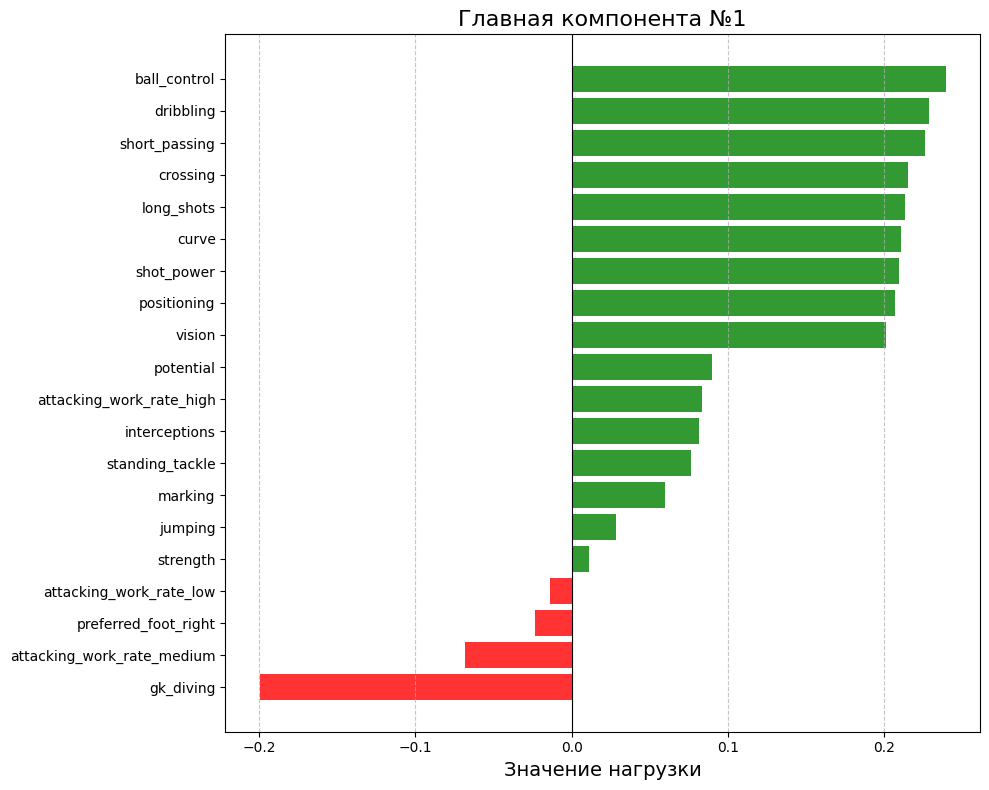

In [40]:
pca_explanation_plot(loadings, X_scaled.columns, component_number=0)

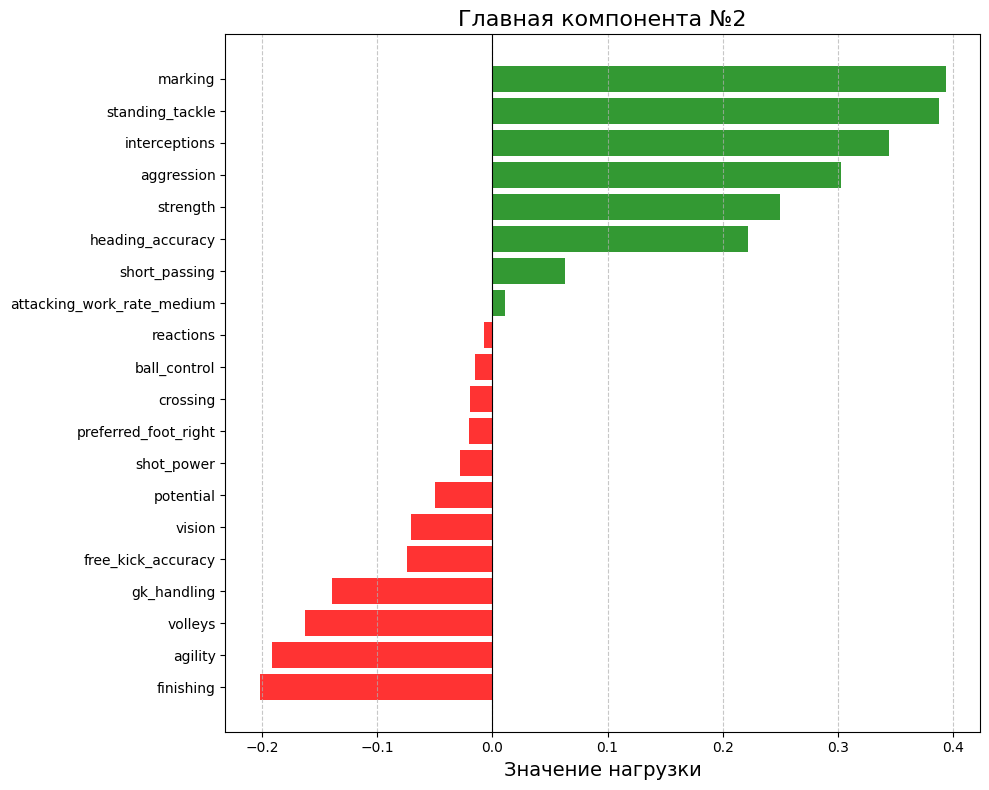

In [41]:
pca_explanation_plot(loadings, X_scaled.columns, component_number=1)

#### Кластеры

In [42]:
import seaborn as sns
from sklearn.cluster import MiniBatchKMeans, KMeans, DBSCAN

In [43]:
kmeans = KMeans(n_clusters=2, random_state=42)

In [44]:
kmeans_labels = kmeans.fit_predict(X_pca)

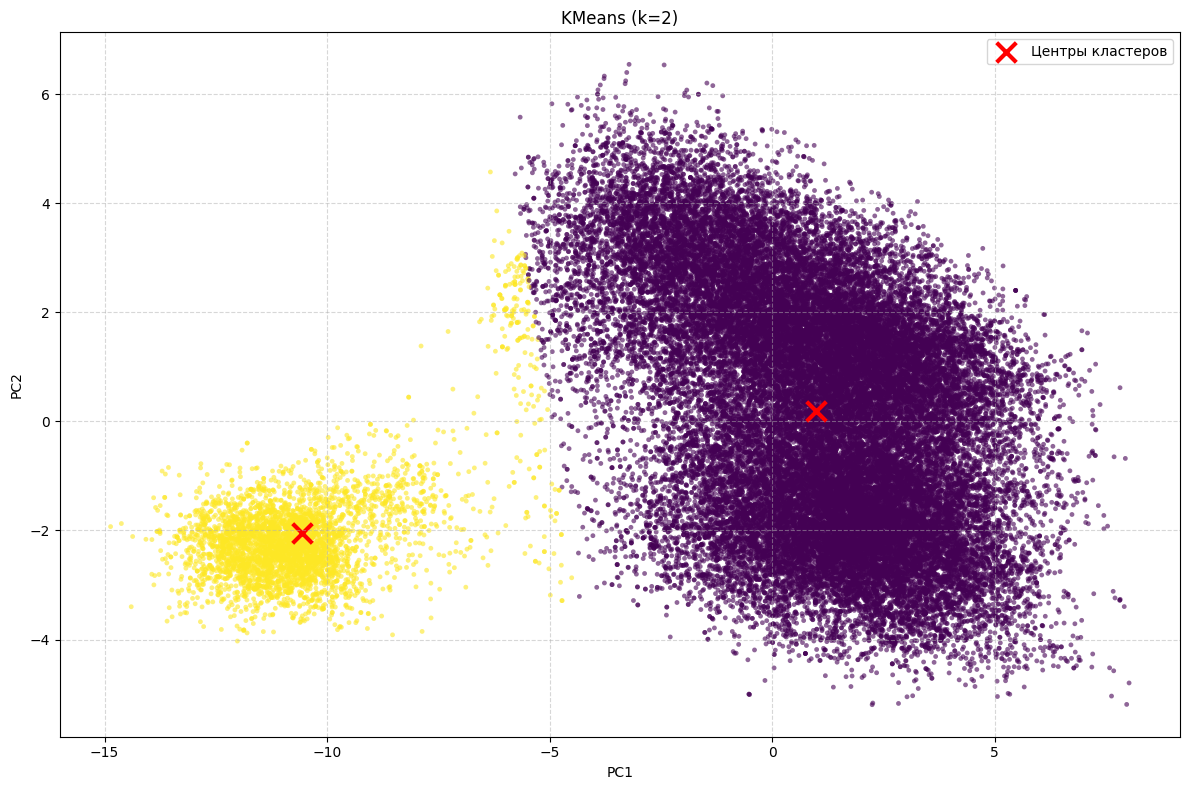

In [45]:
plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap='viridis',
    alpha=0.6,
    s=12,
    edgecolors='none'
)

centers = kmeans.cluster_centers_
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c='red',
    marker='x',
    s=200,
    linewidths=3,
    label='Центры кластеров'
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('KMeans (k=2)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [46]:
unique, counts = np.unique(kmeans_labels, return_counts=True)
for cluster_id, count in zip(unique, counts):
    print(f"Кластер {cluster_id}: {count} игроков ({count/len(kmeans_labels)*100:.1f}%)")

Кластер 0: 44782 игроков (91.4%)
Кластер 1: 4229 игроков (8.6%)


##### K-Means MiniBatch

In [47]:
kmeans_mb = MiniBatchKMeans(
    n_clusters=2,
    random_state=42,
    batch_size=1024,
    reassignment_ratio=0.05
)

In [48]:
kmeans_mb_labels = kmeans_mb.fit_predict(X_pca)

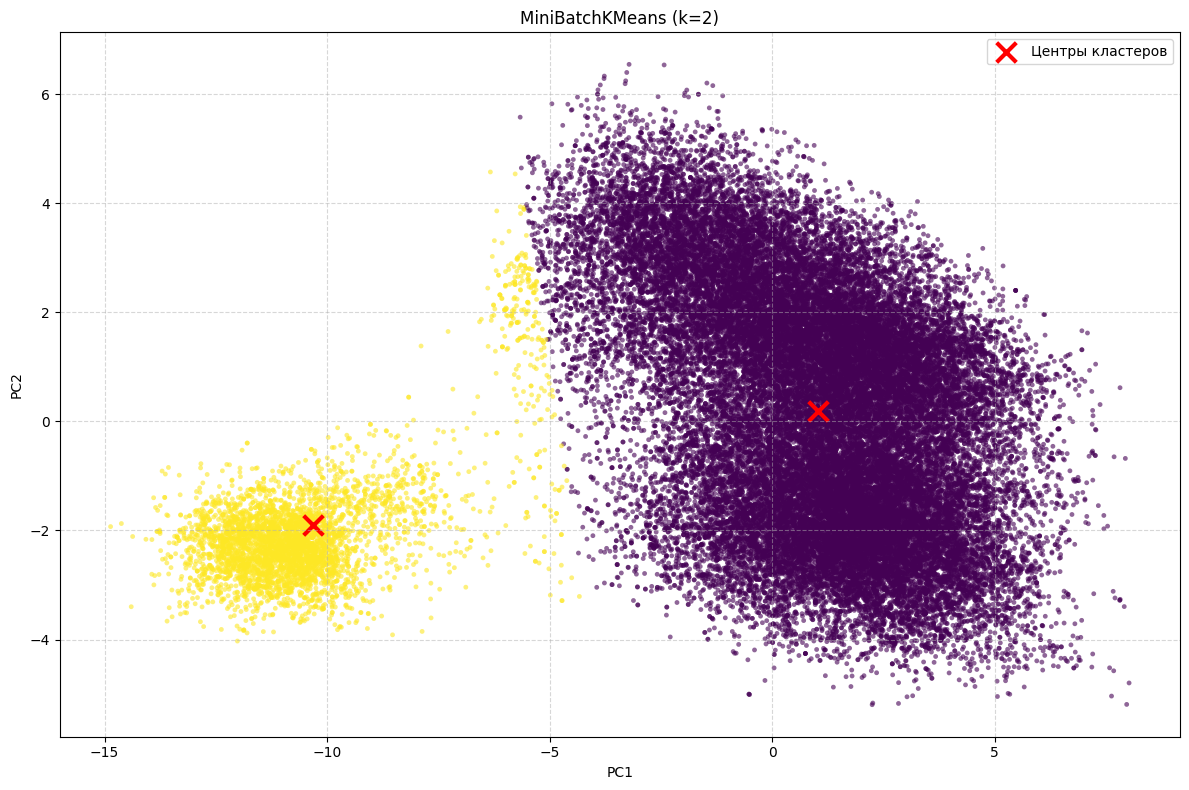

In [49]:
plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_mb_labels,
    cmap='viridis',
    alpha=0.6,
    s=12,
    edgecolors='none'
)

centers = kmeans_mb.cluster_centers_
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c='red',
    marker='x',
    s=200,
    linewidths=3,
    label='Центры кластеров'
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('MiniBatchKMeans (k=2)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### DBSCAN

In [50]:
eps=2
min_samples=1000

In [51]:
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
dbscan_labels = dbscan.fit_predict(X_pca)

In [52]:
n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)

print(f"Найдено кластеров: {n_clusters}")
print(f"Шумных точек: {n_noise} ({n_noise / len(dbscan_labels) * 100:.1f}%)")

Найдено кластеров: 2
Шумных точек: 29 (0.1%)


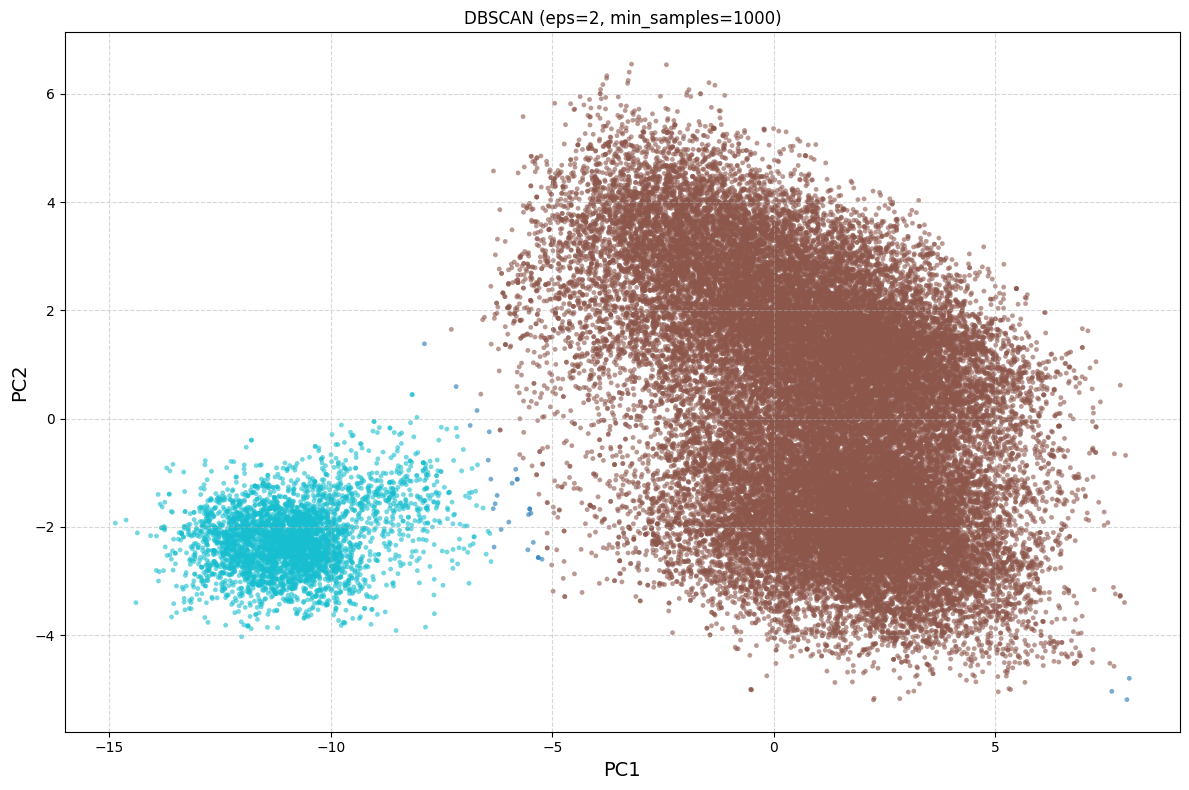

In [53]:
plt.figure(figsize=(12, 8))

colors = dbscan_labels.copy()
colors[colors == -1] = -1

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=dbscan_labels,
    cmap='tab10',
    alpha=0.6,
    s=12,
    edgecolors='none'
)

plt.xlabel('PC1', fontsize=14)
plt.ylabel('PC2', fontsize=14)
plt.title(f'DBSCAN (eps={eps}, min_samples={min_samples})')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

##### plotly

In [54]:
import plotly.express as px

In [55]:
df_plot = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'Cluster': dbscan_labels.astype(str)
})

df_plot['cluster'] = df_plot['Cluster'].replace('-1', 'Noise')
df_plot['Player_Index'] = data.index
df_plot['Potential'] = data['potential'].values

In [56]:
fig = px.scatter(
    df_plot,
    x='PC1',
    y='PC2',
    color='Cluster',
    hover_data=['Player_Index', 'Potential'],
    title=f'DBSCAN (eps={eps}, min_samples={min_samples})<br>'
          f'Кластеров: {len(df_plot[df_plot["Cluster"] != "Noise"]["Cluster"].unique())}, '
          f'Выбросов: {len(df_plot[df_plot["Cluster"] == "Noise"])}',
    width=1000,
    height=800,
    template="plotly_white"
)

fig.update_traces(marker=dict(size=6, opacity=0.7))
fig.update_yaxes(tickfont=dict(size=14, color="black"))
fig.update_xaxes(tickfont=dict(size=14, color="black"))
fig.update_layout(
    legend_title_text='Кластер',
    title_x=0.5,
    font=dict(size=14, color='black')
)

fig.show()